In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
 
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("C:\\Users\\User\\Desktop\\HMDA_2019_2025_70000_CLEAN.csv")

In [3]:
df.head(10)

,activity_year,action_taken,loan_purpose,loan_type,lien_status,construction_method,derived_dwelling_category,occupancy_type,total_units,property_value,loan_amount,income,state_code,county_code,census_tract,derived_msa_md,derived_loan_product_type,interest_rate
0,2019,1,4,1,2,1,Single Family (1-4 Units):Site-Built,1,1,915000,15000.0,202.0,CO,8059.0,8.059010e+09,19740,Conventional:Subordinate Lien,3.24
1,2019,1,31,1,1,1,Single Family (1-4 Units):Site-Built,1,1,505000,375000.0,62.0,CO,8059.0,8.059010e+09,19740,Conventional:First Lien,3.05
2,2019,1,4,1,2,1,Single Family (1-4 Units):Site-Built,1,1,325000,35000.0,32.0,CO,NaN,NaN,0,Conventional:Subordinate Lien,5.99
3,2019,1,4,1,2,1,Single Family (1-4 Units):Site-Built,1,1,425000,15000.0,66.0,CO,8059.0,8.059012e+09,19740,Conventional:Subordinate Lien,3.49
4,2019,1,2,1,1,1,Single Family (1-4 Units):Site-Built,1,1,245000,45000.0,31.0,CO,NaN,NaN,0,Conventional:First Lien,5.74
5,2019,1,4,1,2,1,Single Family (1-4 Units):Site-Built,1,1,375000,45000.0,127.0,CO,8059.0,8.059010e+09,19740,Conventional:Subordinate Lien,5.49
6,2019,1,2,1,2,1,Single Family (1-4 Units):Site-Built,1,1,325000,55000.0,116.0,CO,8001.0,8.001009e+09,19740,Conventional:Subordinate Lien,6.49
7,2019,1,4,1,2,1,Single Family (1-4 Units):Site-Built,1,1,315000,55000.0,86.0,CO,8059.0,8.059010e+09,19740,Conventional:Subordinate Lien,6.49
8,2019,1,31,1,2,1,Single Family (1-4 Units):Site-Built,1,1,355000,85000.0,56.0,CO,8031.0,8.031005e+09,19740,Conventional:Subordinate Lien,6.49
9,2019,1,4,1,2,1,Single Family (1-4 Units):Site-Built,1,1,415000,55000.0,68.0,CO,8123.0,8.123002e+09,24540,Conventional:Subordinate Lien,5.99


In [4]:
df.shape

(70000, 18)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   activity_year              70000 non-null  int64  
 1   action_taken               70000 non-null  int64  
 2   loan_purpose               70000 non-null  int64  
 3   loan_type                  70000 non-null  int64  
 4   lien_status                70000 non-null  int64  
 5   construction_method        70000 non-null  int64  
 6   derived_dwelling_category  70000 non-null  str    
 7   occupancy_type             70000 non-null  int64  
 8   total_units                70000 non-null  str    
 9   property_value             58628 non-null  str    
 10  loan_amount                70000 non-null  float64
 11  income                     53858 non-null  float64
 12  state_code                 68990 non-null  str    
 13  county_code                68541 non-null  float64
 14  c

In [6]:
df["property_value"] = pd.to_numeric(df["property_value"], errors="coerce")   # 'Exempt' becomes empty
df["interest_rate"] = pd.to_numeric(df["interest_rate"], errors="coerce")
 
# keep only owner-occupied, site-built, single-family homes (from the proposal)
df = df[(df["occupancy_type"] == 1) &
        (df["derived_dwelling_category"] == "Single Family (1-4 Units):Site-Built")]
 
df = df.dropna(subset=["property_value", "loan_amount"])                       # target must exist
df = df[df["property_value"].between(df["property_value"].quantile(0.005),
                                     df["property_value"].quantile(0.995))]    # remove extreme values
df["income"] = df["income"].fillna(df["income"].median())                      # fill empty cells
df["interest_rate"] = df["interest_rate"].fillna(df["interest_rate"].median())
 
print("Rows used:", len(df))
 
features = ["activity_year", "loan_amount", "income", "interest_rate",
            "loan_purpose", "loan_type", "lien_status"]
X = df[features]
y = df["property_value"]
 

Rows used: 49729


In [7]:
# STEP 2: LOOK AT THE DATA - IS IT SUITABLE FOR REGRESSION?
# ---------------------------------------------------------------
print("\n" + "=" * 70)
print("STEP 2: DATA CHECK")
print("=" * 70)
print("Enough rows?       ", len(df), "rows ->", "YES" if len(df) > 1000 else "NO")
print("Target is a number? YES (property_value in dollars)")
print("Missing values left after cleaning:", int(df[features].isna().sum().sum()))
 


STEP 2: DATA CHECK
Enough rows?        49729 rows -> YES
Target is a number? YES (property_value in dollars)
Missing values left after cleaning: 0


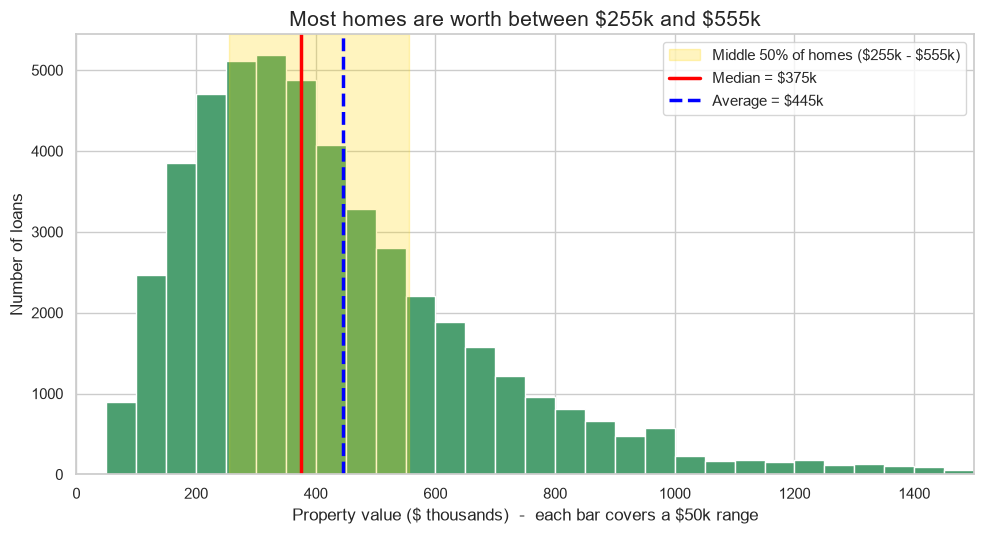


WHAT THIS CHART SHOWS (Graph 1 - Distribution of property value)
- Each bar counts how many homes fall inside a $50k price range. Taller bar = more homes at that price.
- The red line is the MEDIAN ($375k): half of the homes cost less, half cost more.
- The blue dashed line is the AVERAGE ($445k). It sits to the right of the median because a few
  very expensive homes pull the average up.
- The yellow band is the middle 50% of homes: $255k to $555k. This is the 'typical' price range.
- The shape has a long tail to the right (right-skewed): many affordable homes, few very expensive ones.
  Only 1.4% of homes are above $1.5 million (not shown to keep the chart clear).
- Why it matters: a skewed target is one reason plain Linear Regression struggles and tree models do better.



In [8]:
# ---------- GRAPH 1: DISTRIBUTION OF PROPERTY VALUE ----------
values_k = y / 1000                                  # in $ thousands, easier to read
median_k = values_k.median()
mean_k = values_k.mean()
q25, q75 = values_k.quantile(0.25), values_k.quantile(0.75)
share_over = (values_k > 1500).mean() * 100
 
plt.figure(figsize=(10, 5.5))
plt.hist(values_k, bins=range(0, 1550, 50), color="#4C9F70", edgecolor="white")   # one bar = $50k range
plt.axvspan(q25, q75, color="gold", alpha=0.25, label=f"Middle 50% of homes (\\${q25:,.0f}k - \\${q75:,.0f}k)")
plt.axvline(median_k, color="red", linewidth=2.5, label=f"Median = \\${median_k:,.0f}k")
plt.axvline(mean_k, color="blue", linewidth=2.5, linestyle="--", label=f"Average = \\${mean_k:,.0f}k")
plt.xlim(0, 1500)
plt.title("Most homes are worth between \\$%dk and \\$%dk" % (q25, q75), fontsize=15)
plt.xlabel("Property value (\\$ thousands)  -  each bar covers a \\$50k range", fontsize=12)
plt.ylabel("Number of loans", fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig("graph1_distribution.png", dpi=150)
plt.show()
 
print(f"""
WHAT THIS CHART SHOWS (Graph 1 - Distribution of property value)
- Each bar counts how many homes fall inside a $50k price range. Taller bar = more homes at that price.
- The red line is the MEDIAN (${median_k:,.0f}k): half of the homes cost less, half cost more.
- The blue dashed line is the AVERAGE (${mean_k:,.0f}k). It sits to the right of the median because a few
  very expensive homes pull the average up.
- The yellow band is the middle 50% of homes: ${q25:,.0f}k to ${q75:,.0f}k. This is the 'typical' price range.
- The shape has a long tail to the right (right-skewed): many affordable homes, few very expensive ones.
  Only {share_over:.1f}% of homes are above $1.5 million (not shown to keep the chart clear).
- Why it matters: a skewed target is one reason plain Linear Regression struggles and tree models do better.
""")

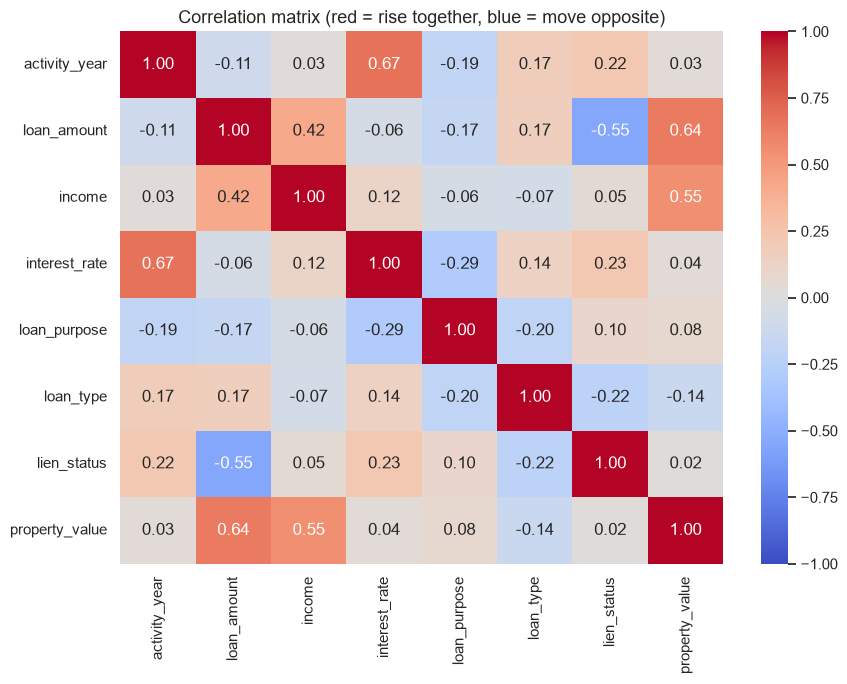


WHAT THIS CHART SHOWS (Graph 2 - Correlation matrix)
- Each square is the link between two columns, from -1 to +1. +1 = they rise together, 0 = no link,
  -1 = one rises while the other falls. Look at the last row/column (property_value).
- Strongest links with property value: loan_amount (0.64) and income (0.55).
  So bigger loans and higher incomes go with more expensive homes.
- Year, interest rate, loan purpose and lien status are almost unrelated on their own (close to 0).
- Conclusion: the data contains real signal, so regression is suitable.



In [9]:
# ---------- GRAPH 2: CORRELATION MATRIX ----------
matrix = df[features + ["property_value"]].corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix (red = rise together, blue = move opposite)", fontsize=13)
plt.tight_layout()
plt.savefig("graph2_correlation.png", dpi=150)
plt.show()
 
corr_target = matrix["property_value"].drop("property_value")
top1 = corr_target.abs().sort_values(ascending=False).index[0]
top2 = corr_target.abs().sort_values(ascending=False).index[1]
print(f"""
WHAT THIS CHART SHOWS (Graph 2 - Correlation matrix)
- Each square is the link between two columns, from -1 to +1. +1 = they rise together, 0 = no link,
  -1 = one rises while the other falls. Look at the last row/column (property_value).
- Strongest links with property value: {top1} ({corr_target[top1]:.2f}) and {top2} ({corr_target[top2]:.2f}).
  So bigger loans and higher incomes go with more expensive homes.
- Year, interest rate, loan purpose and lien status are almost unrelated on their own (close to 0).
- Conclusion: the data contains real signal, so regression is suitable.
""")
 

STEP 3: MODELS


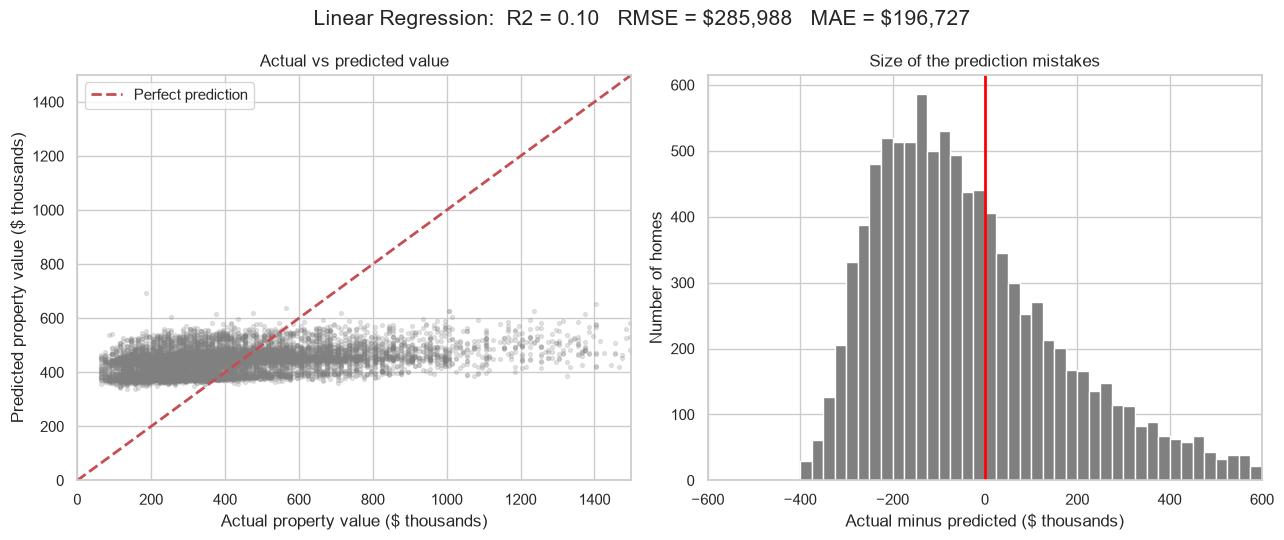


WHAT THESE CHARTS SHOW (Linear Regression)
- R2 = 0.10: the model explains about 10% of the differences in property values.
- RMSE = $285,988: the typical prediction mistake (large mistakes count extra).
- MAE = $196,727: the average prediction mistake.
- 32% of predictions are within $100,000 of the real value.
- LEFT chart: every dot is a home. The red dashed line is perfect prediction. Dots close to the line = good
  predictions; dots far away = bad predictions.
- RIGHT chart: how far off each prediction was. A tall, narrow bar-pile centred on the red zero line means
  small errors; a wide pile means big errors.



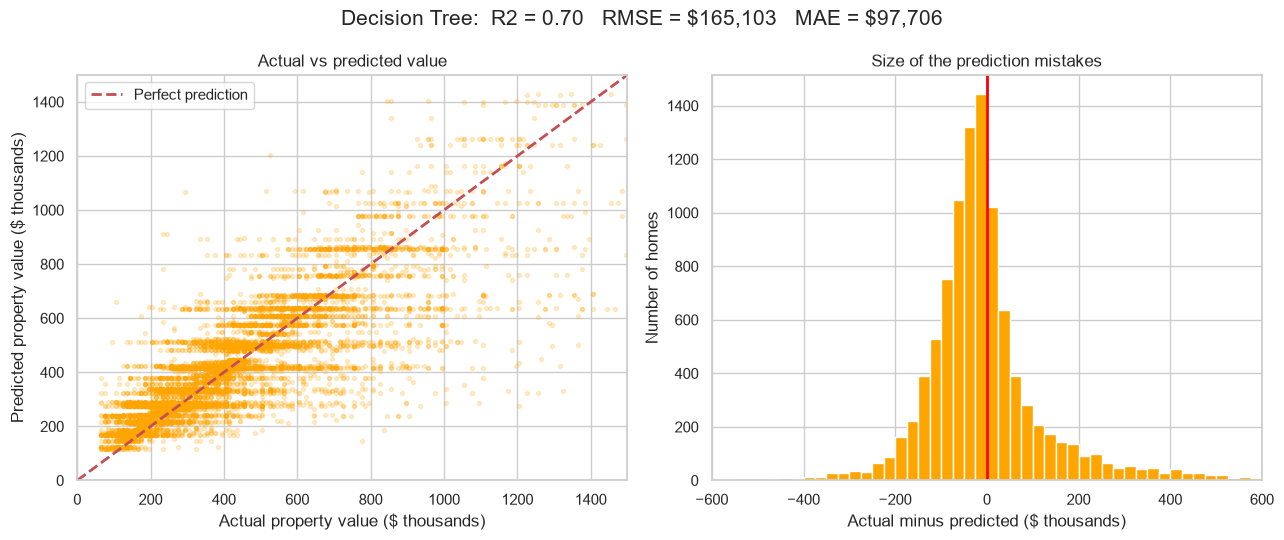


WHAT THESE CHARTS SHOW (Decision Tree)
- R2 = 0.70: the model explains about 70% of the differences in property values.
- RMSE = $165,103: the typical prediction mistake (large mistakes count extra).
- MAE = $97,706: the average prediction mistake.
- 69% of predictions are within $100,000 of the real value.
- LEFT chart: every dot is a home. The red dashed line is perfect prediction. Dots close to the line = good
  predictions; dots far away = bad predictions.
- RIGHT chart: how far off each prediction was. A tall, narrow bar-pile centred on the red zero line means
  small errors; a wide pile means big errors.



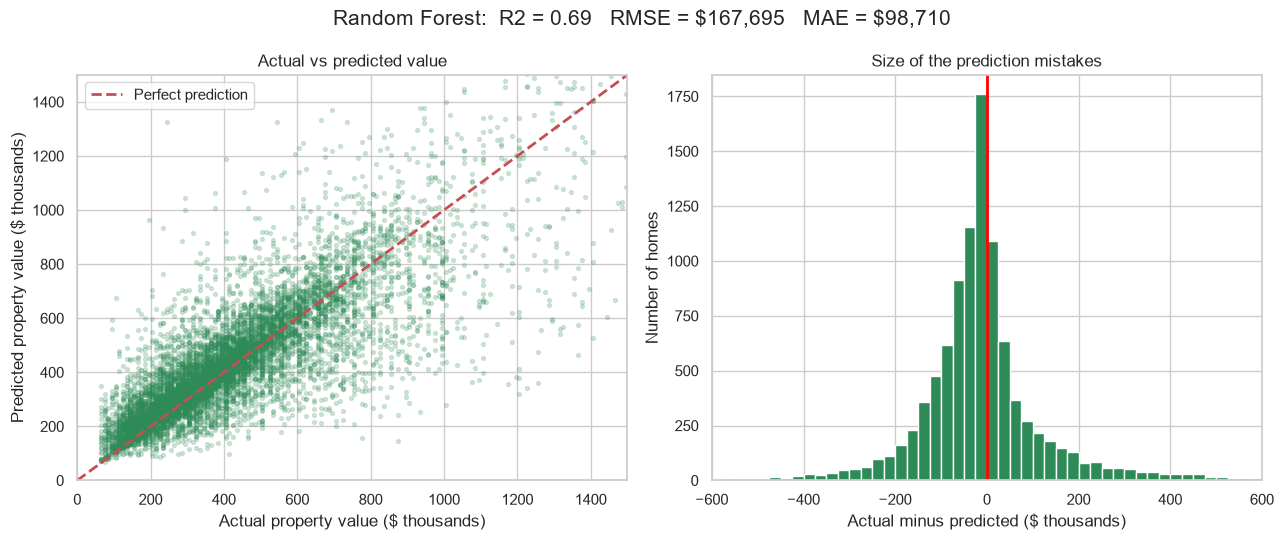


WHAT THESE CHARTS SHOW (Random Forest)
- R2 = 0.69: the model explains about 69% of the differences in property values.
- RMSE = $167,695: the typical prediction mistake (large mistakes count extra).
- MAE = $98,710: the average prediction mistake.
- 68% of predictions are within $100,000 of the real value.
- LEFT chart: every dot is a home. The red dashed line is perfect prediction. Dots close to the line = good
  predictions; dots far away = bad predictions.
- RIGHT chart: how far off each prediction was. A tall, narrow bar-pile centred on the red zero line means
  small errors; a wide pile means big errors.



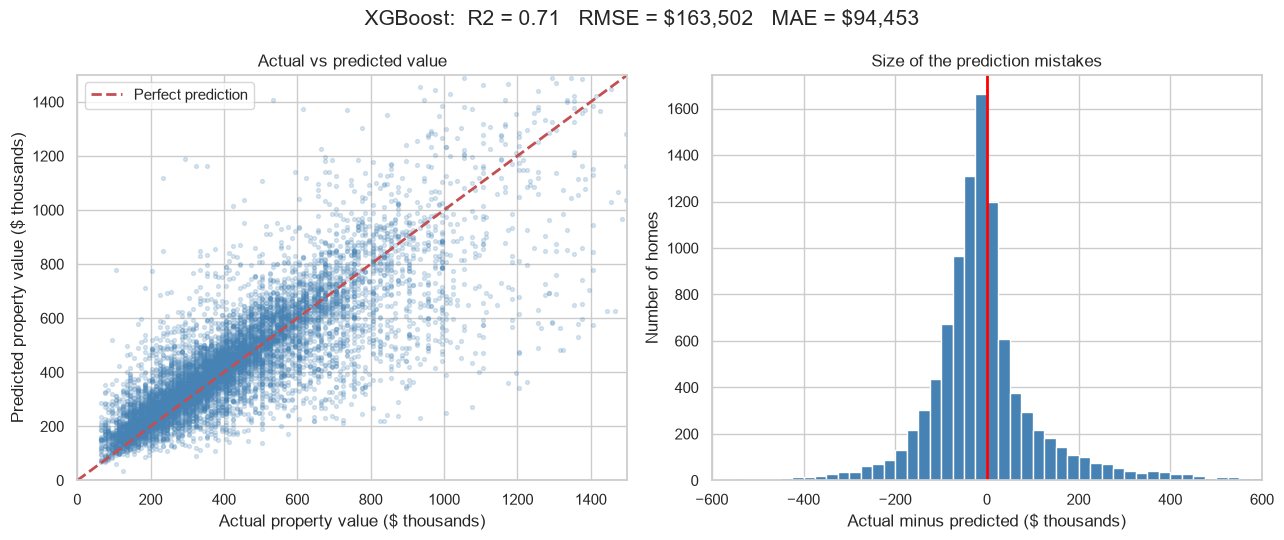


WHAT THESE CHARTS SHOW (XGBoost)
- R2 = 0.71: the model explains about 71% of the differences in property values.
- RMSE = $163,502: the typical prediction mistake (large mistakes count extra).
- MAE = $94,453: the average prediction mistake.
- 71% of predictions are within $100,000 of the real value.
- LEFT chart: every dot is a home. The red dashed line is perfect prediction. Dots close to the line = good
  predictions; dots far away = bad predictions.
- RIGHT chart: how far off each prediction was. A tall, narrow bar-pile centred on the red zero line means
  small errors; a wide pile means big errors.



In [10]:
# STEP 3: TRAIN THE 4 MODELS
# ---------------------------------------------------------------
print("=" * 70)
print("STEP 3: MODELS")
print("=" * 70)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
 
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=200, random_state=42),
}
colors = {"Linear Regression": "gray", "Decision Tree": "orange",
          "Random Forest": "seagreen", "XGBoost": "steelblue"}
 
results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)                         # learn from the training data
    pred = model.predict(X_test)                        # predict homes the model has never seen
    predictions[name] = pred
 
    rmse = np.sqrt(mean_squared_error(y_test, pred))    # typical size of error, big mistakes count more
    mae = mean_absolute_error(y_test, pred)             # average size of error
    r2 = r2_score(y_test, pred)                         # share of price differences explained (0 to 1)
    results.append({"Model": name, "R2": r2, "RMSE": rmse, "MAE": mae})
 
    # ---------- ONE SET OF GRAPHS PER MODEL ----------
    errors = (y_test - pred) / 1000
    fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
 
    # left: actual vs predicted
    ax[0].scatter(y_test / 1000, pred / 1000, alpha=0.2, s=8, color=colors[name])
    ax[0].plot([0, 1500], [0, 1500], "r--", linewidth=2, label="Perfect prediction")
    ax[0].set_xlim(0, 1500)
    ax[0].set_ylim(0, 1500)
    ax[0].set_title("Actual vs predicted value")
    ax[0].set_xlabel("Actual property value ($ thousands)")
    ax[0].set_ylabel("Predicted property value ($ thousands)")
    ax[0].legend()
 
    # right: how big are the mistakes
    ax[1].hist(errors, bins=np.arange(-600, 601, 25), color=colors[name], edgecolor="white")
    ax[1].axvline(0, color="red", linewidth=2)
    ax[1].set_xlim(-600, 600)
    ax[1].set_title("Size of the prediction mistakes")
    ax[1].set_xlabel("Actual minus predicted ($ thousands)")
    ax[1].set_ylabel("Number of homes")
 
    fig.suptitle(f"{name}:  R2 = {r2:.2f}   RMSE = \\${rmse:,.0f}   MAE = \\${mae:,.0f}", fontsize=15)
    plt.tight_layout()
    plt.savefig("model_" + name.replace(" ", "_") + ".png", dpi=150)
    plt.show()
 
    within_100k = (np.abs(y_test - pred) <= 100000).mean() * 100
    print(f"""
WHAT THESE CHARTS SHOW ({name})
- R2 = {r2:.2f}: the model explains about {r2 * 100:.0f}% of the differences in property values.
- RMSE = ${rmse:,.0f}: the typical prediction mistake (large mistakes count extra).
- MAE = ${mae:,.0f}: the average prediction mistake.
- {within_100k:.0f}% of predictions are within $100,000 of the real value.
- LEFT chart: every dot is a home. The red dashed line is perfect prediction. Dots close to the line = good
  predictions; dots far away = bad predictions.
- RIGHT chart: how far off each prediction was. A tall, narrow bar-pile centred on the red zero line means
  small errors; a wide pile means big errors.
""")
 
results = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
best = results.loc[0, "Model"]

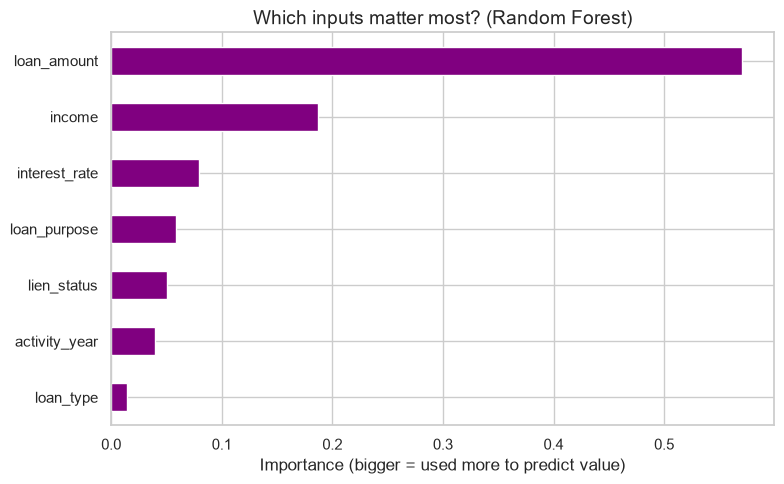


WHAT THIS CHART SHOWS (Feature importance)
- It ranks the inputs by how much the Random Forest relied on them.
- 'loan_amount' is the most important (57%), then 'income'
  (19%).
- Meaning for Nodey: loan size and borrower income are the strongest signals of how much a home is worth.



In [11]:
# Extra graph for Random Forest: which features matter most
importance = pd.Series(models["Random Forest"].feature_importances_, index=features).sort_values()
plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="purple")
plt.title("Which inputs matter most? (Random Forest)", fontsize=14)
plt.xlabel("Importance (bigger = used more to predict value)")
plt.tight_layout()
plt.savefig("graph_feature_importance.png", dpi=150)
plt.show()
print(f"""
WHAT THIS CHART SHOWS (Feature importance)
- It ranks the inputs by how much the Random Forest relied on them.
- '{importance.index[-1]}' is the most important ({importance.iloc[-1] * 100:.0f}%), then '{importance.index[-2]}'
  ({importance.iloc[-2] * 100:.0f}%).
- Meaning for Nodey: loan size and borrower income are the strongest signals of how much a home is worth.
""")
 

STEP 4: MODEL COMPARISON
            Model    R2       RMSE        MAE
          XGBoost 0.706 163501.986  94453.268
    Decision Tree 0.700 165103.092  97705.857
    Random Forest 0.691 167695.211  98710.155
Linear Regression 0.101 285987.821 196726.994
Best model: XGBoost


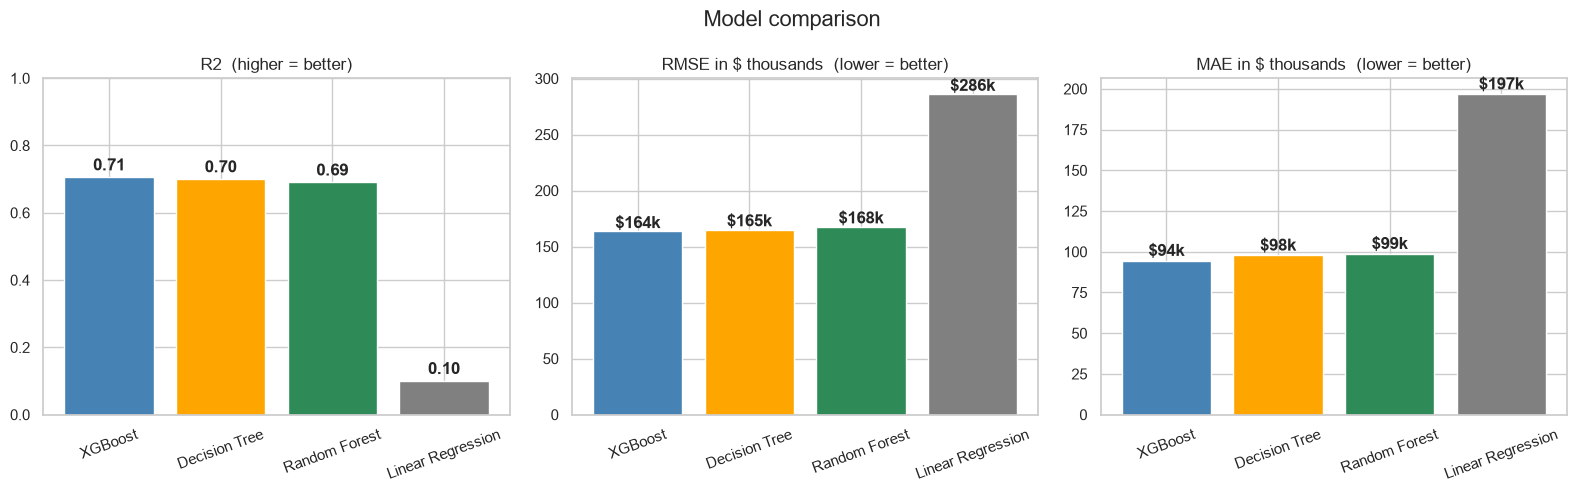


WHAT THIS CHART SHOWS (Model comparison)
- Three scorecards for the same 4 models, tested on the same homes they had never seen.
- R2 (left): share of price differences the model explains. Best = XGBoost (0.71),
  worst = Linear Regression (0.10).
- RMSE (middle) and MAE (right): typical dollar error. XGBoost is off by about $94,453 on average
  (MAE); Linear Regression is off by about $196,727.
- Why Linear Regression loses: property values are not a straight-line function of loan size and income
  (very skewed, errors grow with price). Tree-based models can follow curves and interactions.
- The three tree-based models are close; XGBoost and Random Forest combine many trees so they are usually
  the most stable.



In [12]:
# ---------------------------------------------------------------
# STEP 4: COMPARE ALL MODELS
# ---------------------------------------------------------------
print("=" * 70)
print("STEP 4: MODEL COMPARISON")
print("=" * 70)
print(results.round(3).to_string(index=False))
print("Best model:", best)
 
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
order = results["Model"]
bar_colors = [colors[m] for m in order]
 
ax[0].bar(order, results["R2"], color=bar_colors)
ax[0].set_title("R2  (higher = better)")
ax[0].set_ylim(0, 1)
for i, v in enumerate(results["R2"]):
    ax[0].text(i, v + 0.02, f"{v:.2f}", ha="center", fontweight="bold")
 
ax[1].bar(order, results["RMSE"] / 1000, color=bar_colors)
ax[1].set_title("RMSE in $ thousands  (lower = better)")
for i, v in enumerate(results["RMSE"] / 1000):
    ax[1].text(i, v + 3, f"\\${v:,.0f}k", ha="center", fontweight="bold")
 
ax[2].bar(order, results["MAE"] / 1000, color=bar_colors)
ax[2].set_title("MAE in $ thousands  (lower = better)")
for i, v in enumerate(results["MAE"] / 1000):
    ax[2].text(i, v + 3, f"\\${v:,.0f}k", ha="center", fontweight="bold")
 
for a in ax:
    a.tick_params(axis="x", rotation=20)
fig.suptitle("Model comparison", fontsize=16)
plt.tight_layout()
plt.savefig("graph_model_comparison.png", dpi=150)
plt.show()
 
worst = results.loc[len(results) - 1, "Model"]
print(f"""
WHAT THIS CHART SHOWS (Model comparison)
- Three scorecards for the same 4 models, tested on the same homes they had never seen.
- R2 (left): share of price differences the model explains. Best = {best} ({results.loc[0, 'R2']:.2f}),
  worst = {worst} ({results.loc[len(results) - 1, 'R2']:.2f}).
- RMSE (middle) and MAE (right): typical dollar error. {best} is off by about ${results.loc[0, 'MAE']:,.0f} on average
  (MAE); {worst} is off by about ${results.loc[len(results) - 1, 'MAE']:,.0f}.
- Why Linear Regression loses: property values are not a straight-line function of loan size and income
  (very skewed, errors grow with price). Tree-based models can follow curves and interactions.
- The three tree-based models are close; XGBoost and Random Forest combine many trees so they are usually
  the most stable.
""")

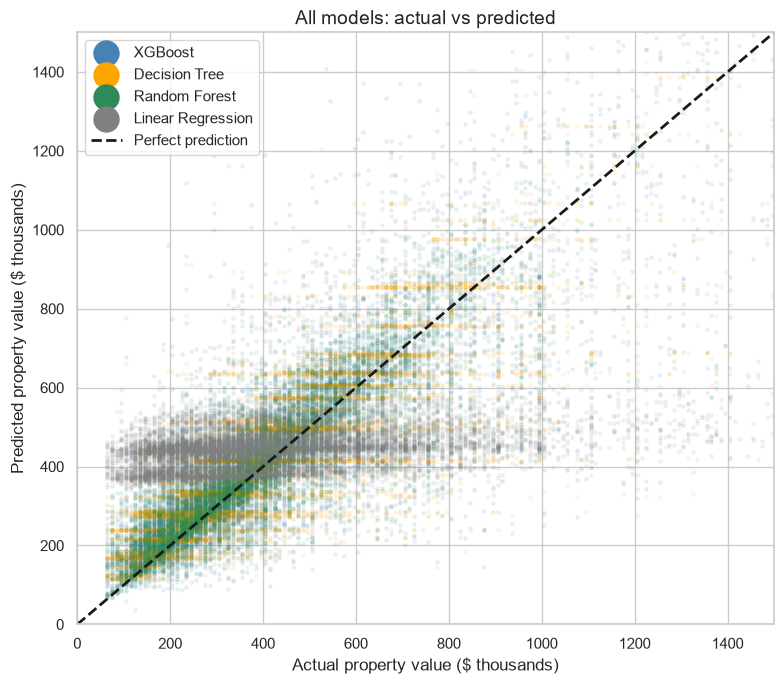


WHAT THIS CHART SHOWS (All models together)
- Every model's predictions are drawn on one picture. The black dashed line is perfect prediction.
- Grey dots (Linear Regression) form a flat band: it predicts roughly the same value (about $400k) for almost
  every home, so it misses both cheap and expensive homes.
- Tree-model dots (orange, green, blue) stay much closer to the line.
- All models struggle more for the most expensive homes (right side).



In [13]:
# Same actual-vs-predicted view, all models on one picture
plt.figure(figsize=(8, 7))
for name in results["Model"]:
    plt.scatter(y_test / 1000, predictions[name] / 1000, alpha=0.08, s=6, color=colors[name])
    plt.scatter([], [], color=colors[name], label=name)     # legend entry with solid colour
plt.plot([0, 1500], [0, 1500], "k--", linewidth=2, label="Perfect prediction")
plt.xlim(0, 1500)
plt.ylim(0, 1500)
plt.title("All models: actual vs predicted", fontsize=14)
plt.xlabel("Actual property value ($ thousands)")
plt.ylabel("Predicted property value ($ thousands)")
plt.legend(markerscale=3)
plt.tight_layout()
plt.savefig("graph_all_models_actual_vs_predicted.png", dpi=150)
plt.show()
print("""
WHAT THIS CHART SHOWS (All models together)
- Every model's predictions are drawn on one picture. The black dashed line is perfect prediction.
- Grey dots (Linear Regression) form a flat band: it predicts roughly the same value (about $400k) for almost
  every home, so it misses both cheap and expensive homes.
- Tree-model dots (orange, green, blue) stay much closer to the line.
- All models struggle more for the most expensive homes (right side).
""")

STEP 5: FASTEST AND SLOWEST GROWING AREAS

State - FASTEST growing:
      State  Growth % per year
Connecticut                7.3
   Colorado                6.3
  Tennessee                6.0
      Idaho                5.4
       Utah                4.9

State - SLOWEST growing:
   State  Growth % per year
  Kansas               -6.9
Arkansas               -5.1
Virginia               -4.1
    Iowa               -2.9
Missouri               -2.6


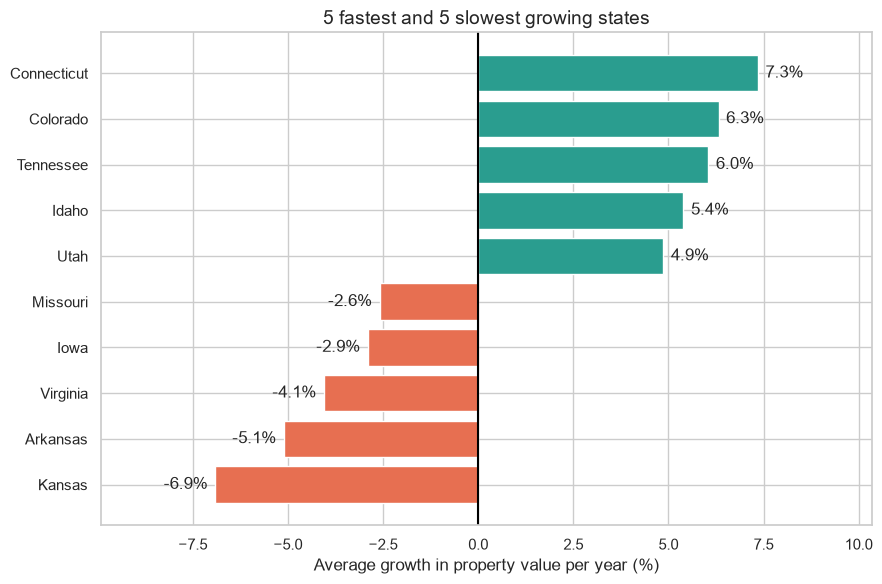


WHAT THIS CHART SHOWS (State growth)
- Green bars = the 5 fastest growing states. Fastest: Connecticut (7.3% a year).
- Orange bars = the 5 slowest growing. Slowest: Kansas (-6.9% a year).
- Growth is the average yearly change in the median property value, 2019-2025.
- Caution: this is a small sample (many areas have only 20-60 loans a year), so a negative number does not
  mean prices really fell. Use it as a rough guide and confirm with the full HMDA data.


City - FASTEST growing:
         City  Growth % per year
        Miami               10.3
New York City                8.6
  Camden (NJ)                8.1
   Providence                7.4
       Denver                6.9

City - SLOWEST growing:
       City  Growth % per year
 Fort Worth               -4.6
 Louisville               -4.3
Kansas City               -3.2
  St. Louis               -3.2
 Pittsburgh               -2.5


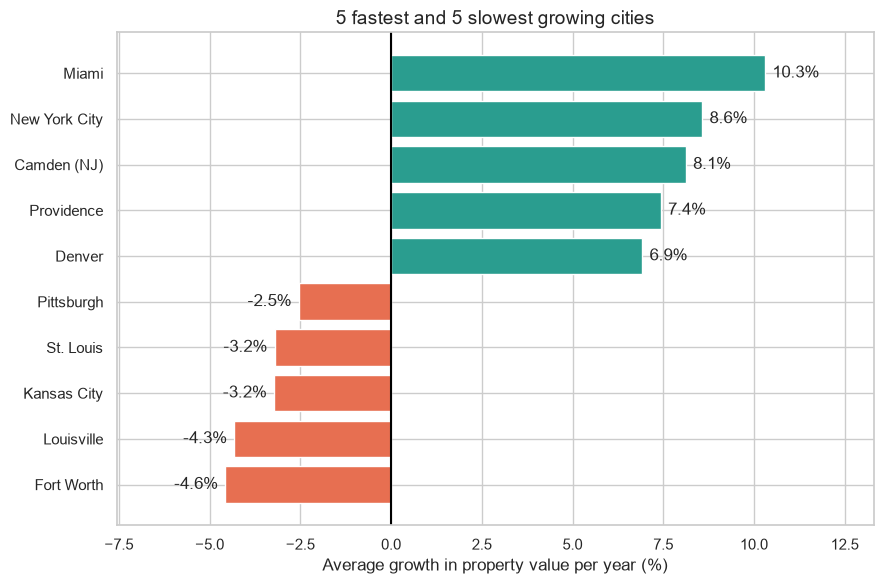


WHAT THIS CHART SHOWS (City growth)
- Green bars = the 5 fastest growing cities. Fastest: Miami (10.3% a year).
- Orange bars = the 5 slowest growing. Slowest: Fort Worth (-4.6% a year).
- Growth is the average yearly change in the median property value, 2019-2025.
- Caution: this is a small sample (many areas have only 20-60 loans a year), so a negative number does not
  mean prices really fell. Use it as a rough guide and confirm with the full HMDA data.



In [17]:
# STEP 5: FASTEST AND SLOWEST GROWING AREAS
# ---------------------------------------------------------------
print("=" * 70)
print("STEP 5: FASTEST AND SLOWEST GROWING AREAS")
print("=" * 70)
 
# full names instead of codes
state_names = {
    "AL": "Alabama", "AK": "Alaska", "AZ": "Arizona", "AR": "Arkansas", "CA": "California",
    "CO": "Colorado", "CT": "Connecticut", "DE": "Delaware", "DC": "District of Columbia",
    "FL": "Florida", "GA": "Georgia", "HI": "Hawaii", "ID": "Idaho", "IL": "Illinois",
    "IN": "Indiana", "IA": "Iowa", "KS": "Kansas", "KY": "Kentucky", "LA": "Louisiana",
    "ME": "Maine", "MD": "Maryland", "MA": "Massachusetts", "MI": "Michigan", "MN": "Minnesota",
    "MS": "Mississippi", "MO": "Missouri", "MT": "Montana", "NE": "Nebraska", "NV": "Nevada",
    "NH": "New Hampshire", "NJ": "New Jersey", "NM": "New Mexico", "NY": "New York",
    "NC": "North Carolina", "ND": "North Dakota", "OH": "Ohio", "OK": "Oklahoma", "OR": "Oregon",
    "PA": "Pennsylvania", "RI": "Rhode Island", "SC": "South Carolina", "SD": "South Dakota",
    "TN": "Tennessee", "TX": "Texas", "UT": "Utah", "VT": "Vermont", "VA": "Virginia",
    "WA": "Washington", "WV": "West Virginia", "WI": "Wisconsin", "WY": "Wyoming",
    "PR": "Puerto Rico",
}
city_names = {
    33124: "Miami", 35614: "New York City", 15804: "Camden (NJ)", 39300: "Providence",
    19740: "Denver", 40140: "Riverside-San Bernardino", 35004: "Nassau-Suffolk (NY)",
    47664: "Warren-Troy (Detroit area)", 27260: "Jacksonville", 31084: "Los Angeles",
    29820: "Las Vegas", 16984: "Chicago", 15764: "Cambridge-Newton (MA)", 40900: "Sacramento",
    38060: "Phoenix", 35084: "Newark (NJ)", 36740: "Orlando", 34980: "Nashville",
    14454: "Boston", 17140: "Cincinnati", 41740: "San Diego", 38900: "Portland (OR)",
    36420: "Oklahoma City", 26900: "Indianapolis", 33460: "Minneapolis", 39580: "Raleigh",
    18140: "Columbus (OH)", 16740: "Charlotte", 33874: "Montgomery-Bucks-Chester (PA)",
    47260: "Virginia Beach", 41700: "San Antonio", 42644: "Seattle", 12420: "Austin",
    12580: "Baltimore", 26420: "Houston", 19124: "Dallas", 40060: "Richmond (VA)",
    37964: "Philadelphia", 38300: "Pittsburgh", 41180: "St. Louis", 28140: "Kansas City",
    31140: "Louisville", 23104: "Fort Worth",
}
 
first = df[df["lien_status"] == 1]          # first-lien loans only, so loan types are comparable
 
# Do the same steps for states and for cities
for column, names, title, plural in [("state_code", state_names, "State", "states"),
                                     ("derived_msa_md", city_names, "City", "cities")]:
    data = first[first[column].notna()]
    if column == "derived_msa_md":
        data = data[~data[column].isin([0, 99999])]          # 0 and 99999 = not in a city area
 
    # median property value of each area in each year (area-years need 20+ loans)
    yearly_area = data.groupby([column, "activity_year"])["property_value"].agg(["median", "count"]).reset_index()
    yearly_area = yearly_area[yearly_area["count"] >= 20]
 
    # growth per year = slope of a trend line through the yearly medians (area needs 5+ years)
    rows = []
    for area, sub in yearly_area.groupby(column):
        if len(sub) >= 5:
            slope = np.polyfit(sub["activity_year"], np.log(sub["median"]), 1)[0]
            rows.append({title: names.get(area, str(area)), "Growth % per year": (np.exp(slope) - 1) * 100})
    table = pd.DataFrame(rows).sort_values("Growth % per year", ascending=False)
 
    fastest = table.head(5)
    slowest = table.tail(5).sort_values("Growth % per year")
    print(f"\n{title} - FASTEST growing:")
    print(fastest.round(1).to_string(index=False))
    print(f"\n{title} - SLOWEST growing:")
    print(slowest.round(1).to_string(index=False))
 
    # chart: 5 fastest (green) and 5 slowest (orange)
    chart = pd.concat([fastest, slowest]).sort_values("Growth % per year")
    bar_colors = ["#2a9d8f" if v >= 0 else "#e76f51" for v in chart["Growth % per year"]]
    plt.figure(figsize=(9, 6))
    plt.barh(chart[title], chart["Growth % per year"], color=bar_colors)
    plt.axvline(0, color="black")
    for i, v in enumerate(chart["Growth % per year"]):
        plt.text(v + (0.2 if v >= 0 else -0.2), i, f"{v:.1f}%", va="center", ha="left" if v >= 0 else "right")
    plt.xlim(chart["Growth % per year"].min() - 3, chart["Growth % per year"].max() + 3)
    plt.title(f"5 fastest and 5 slowest growing {plural}", fontsize=14)
    plt.xlabel("Average growth in property value per year (%)")
    plt.tight_layout()
    plt.savefig(f"graph_growth_{title.lower()}.png", dpi=150)
    plt.show()
 
    print(f"""
WHAT THIS CHART SHOWS ({title} growth)
- Green bars = the 5 fastest growing {plural}. Fastest: {fastest.iloc[0][title]} ({fastest.iloc[0]['Growth % per year']:.1f}% a year).
- Orange bars = the 5 slowest growing. Slowest: {slowest.iloc[0][title]} ({slowest.iloc[0]['Growth % per year']:.1f}% a year).
- Growth is the average yearly change in the median property value, 2019-2025.
- Caution: this is a small sample (many areas have only 20-60 loans a year), so a negative number does not
  mean prices really fell. Use it as a rough guide and confirm with the full HMDA data.
""")

STEP 6: TIME SERIES
activity_year
2019    395000.0
2020    445000.0
2021    235000.0
2022    385000.0
2023    375000.0
2024    395000.0
2025    405000.0
Forecast: {2026: '$386,429', 2027: '$388,929', 2028: '$391,429'}


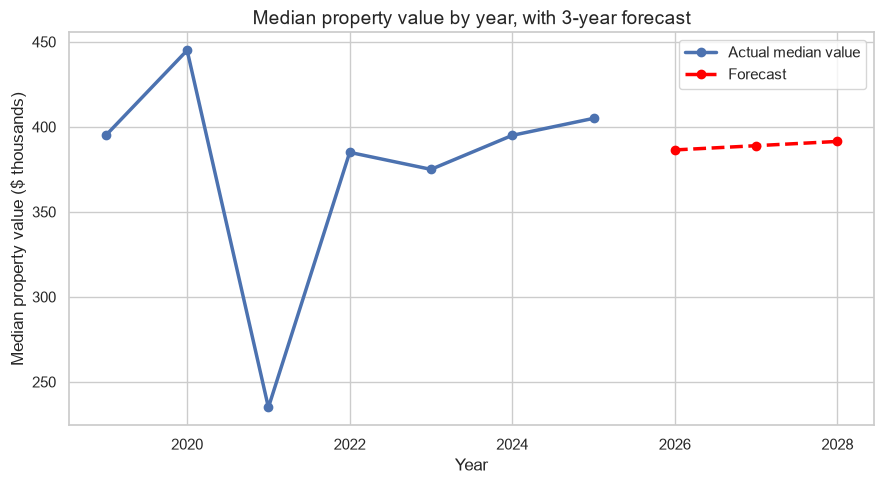


WHAT THIS CHART SHOWS (Time series)
- Blue line: the median property value in each year, 2019-2025.
- Red dashed line: a 3-year forecast from a straight-line trend, reaching about $391,429 in 2028.
- Caution: the sample has a different mix of states in each year (for example 2019 is mostly New Jersey), so
  the yearly medians jump around (see the 2021 dip). Treat the forecast as a rough direction only.



In [15]:
# STEP 6: TIME SERIES (median property value per year)
# ---------------------------------------------------------------
print("=" * 70)
print("STEP 6: TIME SERIES")
print("=" * 70)
yearly = df.groupby("activity_year")["property_value"].median()
print(yearly.to_string())
 
years = yearly.index.values
slope, intercept = np.polyfit(years, yearly.values, 1)       # straight-line trend
last = int(years[-1])
future_years = [last + 1, last + 2, last + 3]
forecast = [slope * yr + intercept for yr in future_years]
print("Forecast:", {yr: f"${v:,.0f}" for yr, v in zip(future_years, forecast)})
 
plt.figure(figsize=(9, 5))
plt.plot(years, yearly.values / 1000, "o-", linewidth=2.5, label="Actual median value")
plt.plot(future_years, np.array(forecast) / 1000, "o--", color="red", linewidth=2.5, label="Forecast")
plt.title("Median property value by year, with 3-year forecast", fontsize=14)
plt.xlabel("Year")
plt.ylabel("Median property value ($ thousands)")
plt.legend()
plt.tight_layout()
plt.savefig("graph_time_series.png", dpi=150)
plt.show()
print(f"""
WHAT THIS CHART SHOWS (Time series)
- Blue line: the median property value in each year, 2019-{last}.
- Red dashed line: a 3-year forecast from a straight-line trend, reaching about ${forecast[-1]:,.0f} in {future_years[-1]}.
- Caution: the sample has a different mix of states in each year (for example 2019 is mostly New Jersey), so
  the yearly medians jump around (see the 2021 dip). Treat the forecast as a rough direction only.
""")

In [16]:
# STEP 7: HYPOTHESIS TESTS  (if p-value < 0.05 we REJECT H0)
# ---------------------------------------------------------------
print("=" * 70)
print("STEP 7: HYPOTHESIS TESTS")
print("=" * 70)
 
# Test 1
r, p1 = stats.spearmanr(df["loan_amount"], df["property_value"])
print("\nTest 1: Does loan amount relate to property value?")
print("  H0: there is NO relationship      H1: there IS a relationship")
print(f"  correlation = {r:.2f}, p-value = {p1:.4f}")
print("  Result:", "Reject H0 -> relationship is real, regression can work." if p1 < 0.05
      else "Fail to reject H0 -> no relationship found.")
 
# Test 2
err_linear = abs(y_test - predictions["Linear Regression"])
err_forest = abs(y_test - predictions["Random Forest"])
stat, p2 = stats.wilcoxon(err_linear, err_forest)
print("\nTest 2: Is Random Forest different from Linear Regression?")
print("  H0: both models make the same size of errors      H1: errors are different")
print(f"  average error: Linear ${err_linear.mean():,.0f} vs Forest ${err_forest.mean():,.0f}, p-value = {p2:.4f}")
print("  Result:", "Reject H0 -> the models really differ (lower error is better)." if p2 < 0.05
      else "Fail to reject H0 -> models are about the same.")
 
# Test 3
r3, p3 = stats.spearmanr(df["activity_year"], df["property_value"])
print("\nTest 3: Do property values change over the years?")
print("  H0: NO trend over time      H1: there IS a trend")
print(f"  correlation = {r3:.2f}, p-value = {p3:.4f}")
print("  Result:", "Reject H0 -> values change over time." if p3 < 0.05
      else "Fail to reject H0 -> no trend found.")

STEP 7: HYPOTHESIS TESTS

Test 1: Does loan amount relate to property value?
  H0: there is NO relationship      H1: there IS a relationship
  correlation = 0.64, p-value = 0.0000
  Result: Reject H0 -> relationship is real, regression can work.

Test 2: Is Random Forest different from Linear Regression?
  H0: both models make the same size of errors      H1: errors are different
  average error: Linear $196,727 vs Forest $98,710, p-value = 0.0000
  Result: Reject H0 -> the models really differ (lower error is better).

Test 3: Do property values change over the years?
  H0: NO trend over time      H1: there IS a trend
  correlation = 0.03, p-value = 0.0000
  Result: Reject H0 -> values change over time.
